# Комаров Максим

In [1]:
import os
for variable in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS',
                 'NUMEXPR_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS'):
    os.environ[variable] = '2'

from pathlib import Path
from hashlib import sha256
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 12)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.float_format', lambda value: f'{value:.3f}')
sns.set_theme(style='whitegrid', font='DejaVu Sans', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'grid.alpha': 0.18})
ROOT = Path.cwd()
if not (ROOT / 'NHL-playoffs-2026.xlsx').exists():
    ROOT = ROOT / 'homework' / 'final_exam'
DATA_PATH = ROOT / 'NHL-playoffs-2026.xlsx'
FIGURES = ROOT / 'figures'
FIGURES.mkdir(exist_ok=True)

def say(text):
    display(Markdown(text))

def show(table, rename=None):
    result = table.copy()
    if rename:
        result = result.rename(columns=rename)
    if isinstance(result.index, pd.RangeIndex) and result.index.start == 0:
        result.index = pd.RangeIndex(1, len(result) + 1, name='№')
    display(result)

def save_figure(name):
    plt.savefig(FIGURES / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()

# Исправление кодировки касается только отображаемых имён, а не ключей расчёта.
def readable_name(value):
    if not isinstance(value, str) or not any(c in value for c in ('Ã', 'Å', 'Ä')):
        return value
    for encoding in ('latin1', 'cp1252'):
        try:
            return value.encode(encoding).decode('utf-8')
        except (UnicodeEncodeError, UnicodeDecodeError):
            pass
    return value

## 1. Чтение и проверка данных

In [2]:
excel = pd.ExcelFile(DATA_PATH)
assert excel.sheet_names == ['Sheet1']
raw = pd.read_excel(excel, sheet_name='Sheet1')
assert np.array_equal(raw['Unnamed: 0'].to_numpy(), np.arange(len(raw)))
events = raw.drop(columns='Unnamed: 0').copy()
events['Date'] = pd.to_datetime(events['Date'])
assert events.shape == (29710, 38)
assert not events.duplicated(['Game ID', 'Play ID']).any()
assert events['Dataset'].unique().tolist() == ['NHL 2026 playoffs']
assert events['Period'].ge(1).all()
assert events.groupby(['Game ID', 'Period'])["Home Team's Defending Side"].nunique().eq(1).all()
INPUT_HASH = sha256(DATA_PATH.read_bytes()).hexdigest()
say(f'**{len(events):,} событий, {events.shape[1]} колонок, '
    f'{events["Game ID"].nunique()} матча.** Период: '
    f'{events["Date"].min():%d.%m.%Y}–{events["Date"].max():%d.%m.%Y}.')
show(events[['Date', 'Away Team', 'Home Team', 'Remaining Time', 'Play Type']].head(10))
show(events['Play Type'].value_counts().rename_axis('Тип события').to_frame('Число событий'))
show(pd.DataFrame({'Поле': events.columns, 'Тип': events.dtypes.astype(str).values,
                   'Пропусков': events.isna().sum().values}))
say(f'SHA256 исходного Excel: `{INPUT_HASH}`.')

**29,710 событий, 38 колонок, 82 матча.** Период: 18.04.2026–14.06.2026.

,Date,Away Team,Home Team,Remaining Time,Play Type
№,,,,,
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
2,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit


,Число событий
Тип события,
hit,5621
faceoff,4995
shot-on-goal,4137
stoppage,3958
blocked-shot,2798
missed-shot,2643
giveaway,2604
penalty,804
takeaway,779


,Поле,Тип,Пропусков
№,,,
1,Dataset,str,0
2,Game ID,int64,0
3,Date,datetime64[us],0
4,Away Team,str,0
5,Home Team,str,0
6,Cumulated Away Score,int64,0
7,Cumulated Home Score,int64,0
8,Period,int64,0
9,Elapsed Time,str,0


SHA256 исходного Excel: `dab4dfdd43665f0b10a363654151f03221768818542e1c82d4de5f8c511de421`.

## 2. Сводка по матчам
Одна строка соответствует одной игре. Дату и команды проверяю на постоянство внутри матча. Итоговый счёт беру из последней записи `game-end`, а затем независимо сверяю с количеством событий `goal` каждой команды. Число овертаймов равно максимальному номеру периода минус три, но не меньше нуля.

In [3]:
ordered = events.sort_values(['Game ID', 'Play ID'])
assert events.groupby('Game ID')[['Date', 'Away Team', 'Home Team']].nunique().eq(1).all().all()
ends = ordered.loc[ordered['Play Type'].eq('game-end')].set_index('Game ID')
assert ends.index.is_unique and len(ends) == events['Game ID'].nunique()
games = ends[['Date', 'Away Team', 'Home Team', 'Cumulated Away Score',
              'Cumulated Home Score']].rename(columns={
    'Cumulated Away Score': 'Away Score', 'Cumulated Home Score': 'Home Score'})
games['Overtimes'] = (events.groupby('Game ID')['Period'].max() - 3).clip(lower=0)
games['Outcome'] = games['Overtimes'].map(
    lambda n: 'Final' if n == 0 else ('Final/OT' if n == 1 else f'Final/{n}OT'))
goals = events.loc[events['Play Type'].eq('goal')].copy()
goal_counts = goals.groupby(['Game ID', 'Team Making the Play']).size()
for side in ('Away', 'Home'):
    keys = pd.MultiIndex.from_arrays([games.index, games[f'{side} Team']])
    counted = goal_counts.reindex(keys, fill_value=0).to_numpy()
    np.testing.assert_array_equal(counted, games[f'{side} Score'])
assert games['Away Score'].ne(games['Home Score']).all()
with pd.option_context('display.max_rows', 90):
    show(games)
say('Счёт всех 82 матчей совпал с подсчётом голевых событий. '
    'Полная таблица выше включает число овертаймов отдельно от текстового исхода.')

,Date,Away Team,Home Team,Away Score,Home Score,Overtimes,Outcome
Game ID,,,,,,,
2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,3,4,0,Final
2025030112,2026-04-21,Boston Bruins,Buffalo Sabres,4,2,0,Final
2025030113,2026-04-23,Buffalo Sabres,Boston Bruins,3,1,0,Final
2025030114,2026-04-26,Buffalo Sabres,Boston Bruins,6,1,0,Final
2025030115,2026-04-28,Boston Bruins,Buffalo Sabres,2,1,1,Final/OT
2025030116,2026-05-01,Buffalo Sabres,Boston Bruins,4,1,0,Final
2025030121,2026-04-19,Montréal Canadiens,Tampa Bay Lightning,4,3,1,Final/OT
2025030122,2026-04-21,Montréal Canadiens,Tampa Bay Lightning,2,3,1,Final/OT
2025030123,2026-04-24,Tampa Bay Lightning,Montréal Canadiens,2,3,1,Final/OT


Счёт всех 82 матчей совпал с подсчётом голевых событий. Полная таблица выше включает число овертаймов отдельно от текстового исхода.

## 3. Функция `gameInfo(gameId)`
Возвращаю строку в формате задания: хозяева, гости, счёт в том же порядке, исход и дата. Функция обращается к одной строке сводной таблицы по идентификатору игры.

In [4]:
def gameInfo(gameId):
    game = games.loc[gameId]
    return (f'{game["Home Team"]} - {game["Away Team"]} '
            f'({game["Home Score"]} - {game["Away Score"]}, '
            f'{game["Outcome"]}, {game["Date"]:%Y-%m-%d})')

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


## 4. Суммарное число голов за матч
Складываю итоговый счёт хозяев и гостей. Стандартное отклонение в `describe()` выборочное, с делением на $n-1$.

In [5]:
games['Total Score'] = games['Away Score'] + games['Home Score']
score_summary = games['Total Score'].describe()
show(score_summary.rename_axis('Статистика').to_frame('Голов за матч'))
say(f'Всего забито **{games["Total Score"].sum()} голов**. В среднем за матч — '
    f'**{score_summary["mean"]:.2f}**, медиана — **{score_summary["50%"]:.0f}**.')

,Голов за матч
Статистика,
count,82.000
mean,5.927
std,2.260
min,1.000
25%,5.000
50%,6.000
75%,7.000
max,15.000


Всего забито **486 голов**. В среднем за матч — **5.93**, медиана — **6**.

## 5. Распределение числа голов
Показатель дискретный, поэтому каждому целому числу голов соответствует отдельный столбец.

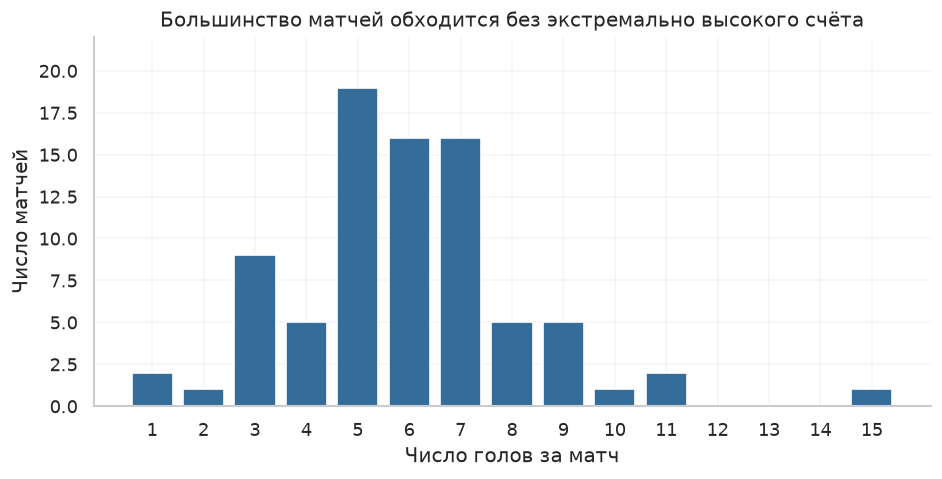

В **51 из 82 матчей (62.2%)** забито от 5 до 7 голов. Модальные значения: 5. Правый хвост соответствует редким очень результативным играм. По одной гистограмме нельзя заключить, что распределение нормальное.

In [6]:
score_frequency = games['Total Score'].value_counts().reindex(
    range(games['Total Score'].min(), games['Total Score'].max() + 1), fill_value=0).sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(score_frequency.index, score_frequency.values, color='#356d9a', width=0.8)
ax.set(xticks=score_frequency.index, xlabel='Число голов за матч', ylabel='Число матчей',
       ylim=(0, score_frequency.max() * 1.16), title='Большинство матчей обходится без экстремально высокого счёта')
save_figure('05_total_goals')
central = games['Total Score'].between(5, 7).sum()
say(f'В **{central} из {len(games)} матчей ({central / len(games):.1%})** забито от 5 до 7 голов. '
    f'Модальные значения: {", ".join(map(str, games["Total Score"].mode()))}. '
    'Правый хвост соответствует редким очень результативным играм. '
    'По одной гистограмме нельзя заключить, что распределение нормальное.')

## 6. Самые результативные и нерезультативные игры
Выбираю все матчи с минимальным и максимальным суммарным счётом. `idxmin()` и `idxmax()` здесь потеряли бы совпадения.

In [7]:
low_ids = games.index[games['Total Score'].eq(games['Total Score'].min())]
high_ids = games.index[games['Total Score'].eq(games['Total Score'].max())]
say('**Меньше всего голов:**\n\n' + '\n'.join(f'- {gameInfo(gid)}' for gid in low_ids))
say('**Больше всего голов:**\n\n' + '\n'.join(f'- {gameInfo(gid)}' for gid in high_ids))

**Меньше всего голов:**

- Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
- Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)

**Больше всего голов:**

- Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)

## 7. Число участников каждой игры
Разворачиваю шесть колонок состава и отдельное поле вратаря для каждой стороны. Удаляю только пустые имена и повторы тройки «матч, команда, игрок». Вратарь уже встречается среди шести игроков на льду, поэтому суммировать непустые ячейки было бы неверно. Полученная таблица участий понадобится и для знаменателя в пунктах 19–20.

In [8]:
appearance_parts = []
for side in ('Away', 'Home'):
    lineup = [f"{side} Team's Player on the Ice #{i}" for i in range(1, 7)]
    lineup.append(f"{side} Team's Goalie")
    part = events[['Game ID', f'{side} Team', *lineup]].melt(
        id_vars=['Game ID', f'{side} Team'], value_vars=lineup, value_name='Player')
    part = part.rename(columns={f'{side} Team': 'Team'}).drop(columns='variable')
    appearance_parts.append(part.dropna(subset=['Player']).drop_duplicates())
appearances = pd.concat(appearance_parts, ignore_index=True).drop_duplicates()
assert not appearances.duplicated(['Game ID', 'Team', 'Player']).any()
player_counts = appearances.groupby('Game ID').size().rename('Player Count')
games['Player Count'] = player_counts
most_players = games.loc[games['Player Count'].eq(games['Player Count'].max()), ['Player Count']].copy()
most_players.insert(0, 'Game Info', most_players.index.map(gameInfo))
show(most_players, {'Game Info': 'Матч', 'Player Count': 'Участников'})
selected_rosters = appearances.loc[appearances['Game ID'].isin(most_players.index)]
show(selected_rosters.groupby(['Game ID', 'Team']).size().to_frame('Участников'))
sample_lineups = [f"{side} Team's Player on the Ice #{i}" for side in ('Away', 'Home') for i in range(1, 7)]
sample_names = pd.unique(events.loc[events['Game ID'].eq(2025030216), sample_lineups].to_numpy().ravel())
assert len(sample_names) == 41 and pd.isna(sample_names).sum() == 1
say('**Важное отличие от примера в PDF:** максимум — 40 реальных игроков, '
    'по 20 у каждой команды. В примере для этого же матча указано 41. '
    'На выданном файле число 41 воспроизводится, если включить NaN в число '
    'уникальных значений состава. Пустая ячейка не является участником, поэтому её не считаю.')
say('Состав считаю по всем наблюдаемым выходам в матче, а не по одному событию. '
    'Это участники, зафиксированные в выгрузке, а не полный заявочный список с запасными.')

,Матч,Участников
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Final, 2026-05-16)",40


Участников
Game ID    Team                          
2025030216 Buffalo Sabres              20
           Montréal Canadiens          20

**Важное отличие от примера в PDF:** максимум — 40 реальных игроков, по 20 у каждой команды. В примере для этого же матча указано 41. На выданном файле число 41 воспроизводится, если включить NaN в число уникальных значений состава. Пустая ячейка не является участником, поэтому её не считаю.

Состав считаю по всем наблюдаемым выходам в матче, а не по одному событию. Это участники, зафиксированные в выгрузке, а не полный заявочный список с запасными.

## 8. Расстояние от броска до створа ворот
Створ — вертикальный отрезок от $(X,-3)$ до $(X,3)$, где $X$ равно $89$ или $-89$ футов. Ближайшая к броску точка имеет координату $y_*=\operatorname{clip}(y,-3,3)$, поэтому формула из задания записывается компактно:

$$d(x,y)=\sqrt{(x-X)^2+(y-y_*)^2}.$$

Когда хозяева защищают левые ворота, они бросают в правые, а гости — в левые. При правой стороне защиты хозяев направления меняются. Направление определяю по данным каждого события, а не по знаку координаты броска: дальний бросок может быть со своей половины.

In [9]:
UNBLOCKED = ['shot-on-goal', 'goal', 'missed-shot']
ATTEMPTS = [*UNBLOCKED, 'blocked-shot']
XCOL, YCOL = 'X Coordinate on the Ice Rink', 'Y Coordinate on the Ice Rink'
shots = events.loc[events['Play Type'].isin(UNBLOCKED)].copy()
assert shots[[XCOL, YCOL, 'Team Making the Play']].notna().all().all()
assert (shots['Team Making the Play'].eq(shots['Home Team']) |
        shots['Team Making the Play'].eq(shots['Away Team'])).all()
assert shots["Home Team's Defending Side"].isin(['left', 'right']).all()
home_shot = shots['Team Making the Play'].eq(shots['Home Team'])
home_defends_left = shots["Home Team's Defending Side"].eq('left')
shots['Goal X'] = np.where(home_shot.eq(home_defends_left), 89.0, -89.0)
shots['Shot Length'] = np.hypot(shots[XCOL] - shots['Goal X'],
                                shots[YCOL] - shots[YCOL].clip(-3, 3))
shots['Accurate'] = shots['Play Type'].isin(['shot-on-goal', 'goal'])
events['Shot Length'] = shots['Shot Length'].reindex(events.index)
assert len(shots) == 7266 and np.isfinite(shots['Shot Length']).all()
# Независимая запись трёх ветвей формулы из PDF.
vertical = np.select([shots[YCOL] < -3, shots[YCOL] > 3],
                     [shots[YCOL] + 3, shots[YCOL] - 3], default=0.0)
np.testing.assert_allclose(shots['Shot Length'],
                          np.sqrt((shots[XCOL] - shots['Goal X'])**2 + vertical**2))
test_x = np.array([89, 89, 89, 85, -85])
test_y = np.array([0, 3, -5, 6, -6])
test_goal = np.array([89, 89, 89, 89, -89])
np.testing.assert_allclose(np.hypot(test_x - test_goal, test_y - np.clip(test_y, -3, 3)),
                          [0, 0, 2, 5, 5])
show(shots[['Game ID', 'Play Type', 'Shot Length']].head(8))
show(shots[['Game ID', 'Play Type', 'Shot Length']].tail(5))

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
23,2025030111,shot-on-goal,41.146
24,2025030111,shot-on-goal,2.236
28,2025030111,missed-shot,38.601


,Game ID,Play Type,Shot Length
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926
29707,2025030416,shot-on-goal,49.041


## 9. Длины точных и неточных бросков
Использую одинаковые границы интервалов и нормирую каждую группу отдельно: площадь каждой гистограммы равна единице. В `seaborn` это `stat='density', common_norm=False`. Иначе большая группа выглядела бы выше просто из-за большего числа бросков.

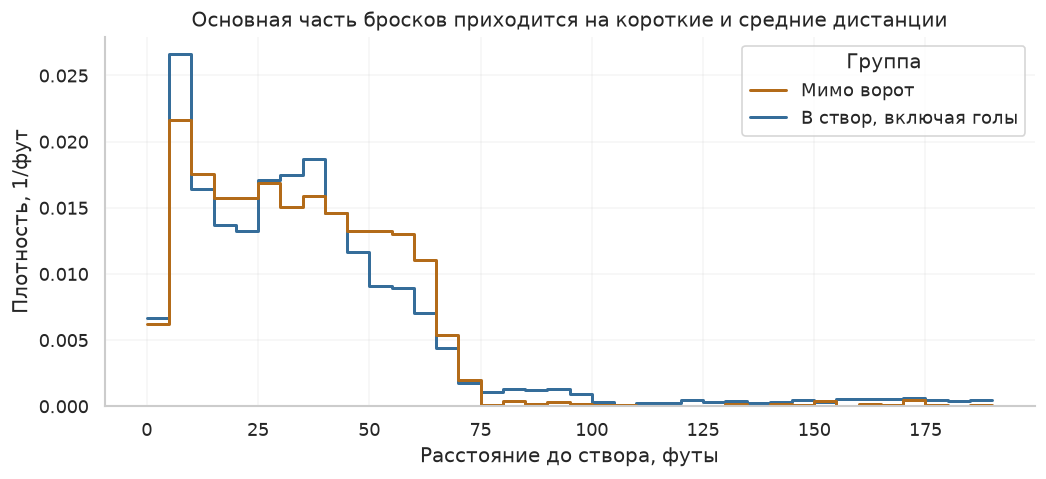

,Бросков,"Среднее, футы","Медиана, футы","Максимум, футы"
Группа,,,,
"В створ, включая голы",4623,36.207,31.828,188.215
Мимо ворот,2643,34.014,32.249,185.068


Медиана точных бросков — **31.8 фута**, промахов — **32.2 фута**. Основные части распределений сильно перекрываются; заметное отличие — длинный хвост точных бросков. Он увеличивает их среднюю дистанцию, поэтому одной средней недостаточно для сравнения.

,Дальше 89 футов
Тип точного броска,
shot-on-goal,202
goal,19


Среди точных бросков **221** сделаны с расстояния больше 89 футов. Такой хвост может возникать при выбросах из своей зоны: если шайба дошла до ворот и вратарь её остановил, событие записано как бросок в створ. Возможны и попытки поразить пустые ворота. Это объяснения механизма, а не доказанные мотивы игроков: в таблице нет признака намерения бросающего. Сравнение гистограмм описывает распределения расстояний при уже известном исходе, а не вероятность попадания на каждой дистанции.

In [10]:
shots['Группа'] = np.where(shots['Accurate'], 'В створ, включая голы', 'Мимо ворот')
bins = np.arange(0, np.ceil(shots['Shot Length'].max() / 5) * 5 + 1, 5)
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(data=shots, x='Shot Length', hue='Группа', bins=bins, stat='density',
             common_norm=False, element='step', fill=False, linewidth=1.8,
             palette=['#b36b19', '#356d9a'], ax=ax)
ax.set(xlabel='Расстояние до створа, футы', ylabel='Плотность, 1/фут', ylim=(0, None),
       title='Основная часть бросков приходится на короткие и средние дистанции')
save_figure('09_shot_distance')
length_summary = shots.groupby('Группа')['Shot Length'].agg(['count', 'mean', 'median', 'max'])
show(length_summary, {'count': 'Бросков', 'mean': 'Среднее, футы',
                      'median': 'Медиана, футы', 'max': 'Максимум, футы'})
say(f'Медиана точных бросков — **{shots.loc[shots["Accurate"], "Shot Length"].median():.1f} фута**, '
    f'промахов — **{shots.loc[~shots["Accurate"], "Shot Length"].median():.1f} фута**. '
    'Основные части распределений сильно перекрываются; заметное отличие — '
    'длинный хвост точных бросков. Он увеличивает их среднюю дистанцию, '
    'поэтому одной средней недостаточно для сравнения.')
long_shots = shots.loc[shots['Accurate'] & shots['Shot Length'].gt(89)]
show(long_shots['Play Type'].value_counts().rename_axis('Тип точного броска').to_frame('Дальше 89 футов'))
say(f'Среди точных бросков **{len(long_shots)}** сделаны с расстояния больше 89 футов. '
    'Такой хвост может возникать при выбросах из своей зоны: если шайба дошла до ворот '
    'и вратарь её остановил, событие записано как бросок в створ. Возможны и попытки '
    'поразить пустые ворота. Это объяснения механизма, а не доказанные мотивы игроков: '
    'в таблице нет признака намерения бросающего. Сравнение гистограмм описывает '
    'распределения расстояний при уже известном исходе, а не вероятность попадания на каждой дистанции.')

## 10. Доля точных бросков команды в каждой игре
Для каждой пары «игра, команда» считаю

$$\text{доля в створ}=\frac{N_{\text{shot-on-goal}}+N_{\text{goal}}}{N_{\text{shot-on-goal}}+N_{\text{goal}}+N_{\text{missed-shot}}}.$$

Заблокированные попытки в знаменатель не входят. Голы входят в числитель. Проверяю наличие двух команд в каждой игре и ненулевой знаменатель. Ниже вывожу все 164 строки.

In [11]:
numshots = shots.groupby(['Game ID', 'Team Making the Play'])['Play Type'].value_counts().unstack(fill_value=0)
numshots = numshots.reindex(columns=UNBLOCKED, fill_value=0)
numshots['On Goal'] = numshots['shot-on-goal'] + numshots['goal']
numshots['Unblocked'] = numshots[UNBLOCKED].sum(axis=1)
assert numshots['Unblocked'].gt(0).all()
numshots['Share of Shots on Goal'] = numshots['On Goal'] / numshots['Unblocked']
assert len(numshots) == 164 and numshots.groupby(level=0).size().eq(2).all()
with pd.option_context('display.max_rows', 170):
    show(numshots[['On Goal', 'missed-shot', 'Unblocked', 'Share of Shots on Goal']],
         {'On Goal': 'В створ', 'missed-shot': 'Мимо', 'Unblocked': 'Незаблокированных',
          'Share of Shots on Goal': 'Доля в створ'})
shares = numshots['Share of Shots on Goal']
say(f'Доля меняется от **{shares.min():.1%}** до **{shares.max():.1%}**, '
    f'медиана по парам «игра, команда» — **{shares.median():.1%}**. '
    'Команды различаются по точности, но одна такая доля не измеряет качество '
    'моментов или вероятность победы: не учитывает блоки, дистанцию и силу соперника.')

Play Type                        В створ  Мимо  Незаблокированных  \
Game ID    Team Making the Play                                     
2025030111 Boston Bruins              20    12                 32   
           Buffalo Sabres             38    18                 56   
2025030112 Boston Bruins              27    17                 44   
           Buffalo Sabres             35    20                 55   
2025030113 Boston Bruins              25    11                 36   
           Buffalo Sabres             30    14                 44   
2025030114 Boston Bruins              24    16                 40   
           Buffalo Sabres             35    19                 54   
2025030115 Boston Bruins              29    17                 46   
           Buffalo Sabres             26    27                 53   
2025030116 Boston Bruins              26    13                 39   
           Buffalo Sabres             26    15                 41   
2025030121 Montréal Canadiens         19    10                 29   
           Tampa Bay Lightning        23    14                 37   
2025030122 Montréal Canadiens         27    14                 41   
           Tampa Bay Lightning        34    19                 53   
2025030123 Montréal Canadiens         29     9                 38   
           Tampa Bay Lightning        17    13                 30   
2025030124 Montréal Canadiens         18    14                 32   
           Tampa Bay Lightning        20    22                 42   
2025030125 Montréal Canadiens         24     9                 33   
           Tampa Bay Lightning        40     7                 47   
2025030126 Montréal Canadiens         30    21                 51   
           Tampa Bay Lightning        33    31                 64   
2025030127 Montréal Canadiens          9    14                 23   
           Tampa Bay Lightning        29    12                 41   
2025030131 Carolina Hurricanes        29    23                 52   
           Ottawa Senators            22    14                 36   
2025030132 Carolina Hurricanes        49    34                 83   
           Ottawa Senators            39    32                 71   
2025030133 Carolina Hurricanes        27    19                 46   
           Ottawa Senators            22    10                 32   
2025030134 Carolina Hurricanes        30    22                 52   
           Ottawa Senators            27    12                 39   
2025030141 Philadelphia Flyers        20    17                 37   
           Pittsburgh Penguins        18    11                 29   
2025030142 Philadelphia Flyers        24     6                 30   
           Pittsburgh Penguins        27    23                 50   
2025030143 Philadelphia Flyers        29    12                 41   
           Pittsburgh Penguins        29    22                 51   
2025030144 Philadelphia Flyers        30    12                 42   
           Pittsburgh Penguins        22    21                 43   
2025030145 Philadelphia Flyers        20    22                 42   
           Pittsburgh Penguins        21    21                 42   
2025030146 Philadelphia Flyers        32     7                 39   
           Pittsburgh Penguins        42    30                 72   
2025030151 Colorado Avalanche         32    17                 49   
           Los Angeles Kings          25    18                 43   
2025030152 Colorado Avalanche         36    22                 58   
           Los Angeles Kings          25    12                 37   
2025030153 Colorado Avalanche         23    19                 42   
           Los Angeles Kings          26    15                 41   
2025030154 Colorado Avalanche         32    15                 47   
           Los Angeles Kings          25    12                 37   
2025030161 Dallas Stars               28     8                 36   
           Minnesota Wild             29     8                 37  

Доля меняется от **35.3%** до **86.0%**, медиана по парам «игра, команда» — **63.9%**. Команды различаются по точности, но одна такая доля не измеряет качество моментов или вероятность победы: не учитывает блоки, дистанцию и силу соперника.

## 11. Пять команд с самой высокой и низкой средней долей
Усредняю доли из пункта 10 с одинаковым весом для каждой игры. Это отличается от отношения суммарных точных бросков к суммарным незаблокированным: во втором случае матчи с большим числом бросков получили бы больший вес. В таблицах оставляю число игр, чтобы было видно, на какой выборке получена оценка.

In [12]:
team_accuracy = shares.groupby(level=1).agg(['mean', 'count']).rename(
    columns={'mean': 'Средняя доля', 'count': 'Матчей'})
avgnumshots = team_accuracy['Средняя доля']
say('**Самые высокие доли:**')
show(team_accuracy.sort_values(['Средняя доля'], ascending=False).head(5))
say('**Самые низкие доли:**')
show(team_accuracy.sort_values(['Средняя доля']).head(5))
say(f'Лидер — **{avgnumshots.idxmax()} ({avgnumshots.max():.1%})**, '
    f'минимум у **{avgnumshots.idxmin()} ({avgnumshots.min():.1%})**. '
    'Высокая точность сама по себе не гарантирует длинный путь в плей-офф: '
    'команды играют разное число матчей и встречаются с разными соперниками. '
    'Рейтинг описывает этот турнир, без проверки статистической значимости различий.')

**Самые высокие доли:**

,Средняя доля,Матчей
Team Making the Play,,
Edmonton Oilers,0.706,6
Philadelphia Flyers,0.684,10
Dallas Stars,0.670,6
Minnesota Wild,0.656,11
Colorado Avalanche,0.653,13


**Самые низкие доли:**

,Средняя доля,Матчей
Team Making the Play,,
Pittsburgh Penguins,0.554,6
Utah Mammoth,0.599,6
Carolina Hurricanes,0.615,19
Tampa Bay Lightning,0.626,7
Buffalo Sabres,0.626,13


Лидер — **Edmonton Oilers (70.6%)**, минимум у **Pittsburgh Penguins (55.4%)**. Высокая точность сама по себе не гарантирует длинный путь в плей-офф: команды играют разное число матчей и встречаются с разными соперниками. Рейтинг описывает этот турнир, без проверки статистической значимости различий.

## 12. Броски в створ и голы в среднем за матч
Броски в створ включают голы. Сначала считаю показатели в каждой игре, затем среднее по играм команды. Здесь нули должны участвовать в среднем наравне с другими результатами.

In [13]:
avgshots = numshots.groupby(level=1)[['On Goal', 'goal']].mean().rename(
    columns={'On Goal': 'Shot', 'goal': 'Goal'})
assert avgshots.shape == (16, 2)
assert np.isfinite(avgshots.to_numpy()).all()
show(avgshots, {'Shot': 'Бросков в створ за матч', 'Goal': 'Голов за матч'})

Play Type,Бросков в створ за матч,Голов за матч
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


## 13. Связь средних бросков и голов
Одна точка — одна команда, всего 16 наблюдений. Строю линейную регрессию по средним из пункта 12. Полоса — 95%-й бутстреп-интервал линии регрессии с фиксированным seed. Дополнительно считаю коэффициент Пирсона и наклон прямой; они помогают описать связь, но не устанавливают причину.

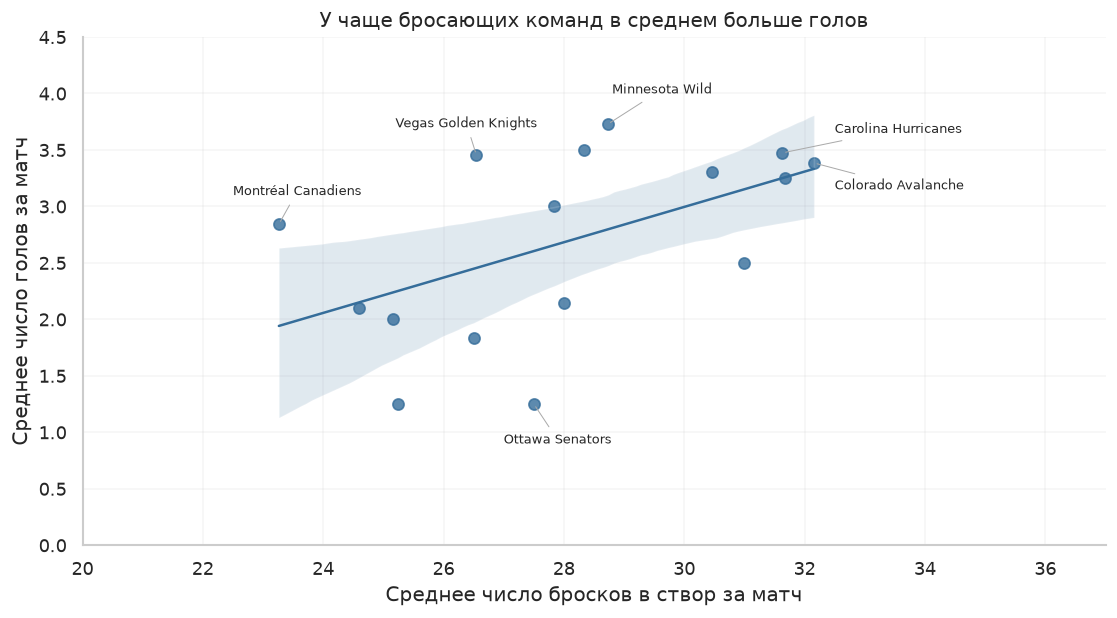

**Связь положительная: r = 0.521, R² = 0.271.** Наклон — 0.156 гола на один дополнительный средний бросок в створ. Разброс вокруг линии остаётся заметным: влияют реализация моментов, соперники и составы. У команд разное число матчей, а сами команды встречаются друг с другом, поэтому эти 16 средних не являются независимым экспериментом. Кроме того, голы входят в число бросков в створ, что создаёт частичную механическую связь.

In [14]:
regression = stats.linregress(avgshots['Shot'], avgshots['Goal'])
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.regplot(data=avgshots, x='Shot', y='Goal', seed=20261024, n_boot=1000,
            scatter_kws={'s': 45}, line_kws={'linewidth': 1.5}, color='#356d9a', ax=ax)
# Выделяю шесть команд, остальные значения доступны в таблице пункта 12.
label_positions = {
    'Carolina Hurricanes': (32.5, 3.65),
    'Colorado Avalanche': (32.5, 3.15),
    'Minnesota Wild': (28.8, 4.0),
    'Vegas Golden Knights': (25.2, 3.7),
    'Montréal Canadiens': (22.5, 3.1),
    'Ottawa Senators': (27.0, 0.9),
}
for team, position in label_positions.items():
    row = avgshots.loc[team]
    ax.annotate(team, (row['Shot'], row['Goal']), xytext=position, fontsize=8,
                arrowprops={'arrowstyle': '-', 'color': '#aaaaaa', 'linewidth': 0.6})
ax.set(xlabel='Среднее число бросков в створ за матч', ylabel='Среднее число голов за матч',
       xlim=(20, 37), ylim=(0, 4.5), title='У чаще бросающих команд в среднем больше голов')
save_figure('13_shots_goals')
say(f'**Связь положительная: r = {regression.rvalue:.3f}, '
    f'R² = {regression.rvalue**2:.3f}.** Наклон — {regression.slope:.3f} гола '
    'на один дополнительный средний бросок в створ. '
    'Разброс вокруг линии остаётся заметным: влияют реализация моментов, '
    'соперники и составы. У команд разное число матчей, а сами команды встречаются '
    'друг с другом, поэтому эти 16 средних не являются независимым экспериментом. '
    'Кроме того, голы входят в число бросков в створ, что создаёт частичную механическую связь.')

## 14. Матч с наибольшим числом попыток броска
Считаю все четыре типа: гол, отражённый бросок в створ, промах, блок. Вывожу все матчи, если максимум разделён. Для диаграммы следующего пункта выбираю первый по `Game ID`.

In [15]:
attempts = events.loc[events['Play Type'].isin(ATTEMPTS)].copy()
attempt_counts = attempts.groupby('Game ID').size()
max_attempt_ids = attempt_counts.index[attempt_counts.eq(attempt_counts.max())]
most_attempts = pd.DataFrame({'Матч': max_attempt_ids.map(gameInfo),
                             'Попыток броска': attempt_counts.loc[max_attempt_ids].to_numpy()},
                            index=max_attempt_ids)
show(most_attempts)
selected_game = int(max_attempt_ids.min())

,Матч,Попыток броска
Game ID,,
2025030132,"Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)",208


## 15. Карта бросков выбранного матча
Хозяева на рисунке атакуют вправо, гости — влево. Если хозяева защищают правые ворота, поворачиваю координаты всех событий этого периода: $(x,y)\mapsto(-x,-y)$. В выбранном матче это действительно нечётные периоды, как сказано в задании; проверяю соответствие явно. Для произвольного матча надёжнее пользоваться стороной защиты, потому что стартовые стороны у команд различаются.

Цвет показывает исход броска, форма маркера — команду. Заблокированные броски показаны в координатах, записанных в выгрузке; точка такого события не обязательно совпадает с исходной точкой выпуска шайбы. Ниже приведена без изменений функция из выданного `rink.py`.

In [16]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def plot_rink(annotations=False):
    plt.gcf().gca().add_artist(plt.Rectangle((-103,-44.5), 206, 89,
                                             linewidth=0,
                                             facecolor='whitesmoke',
                                             zorder=-2))
    # Lines dividing the zones
    line, = plt.plot([0,0], [-42.5,42.5], linewidth=4, solid_capstyle='butt', color='firebrick', zorder=-1)
    plt.scatter([0,0,0,0,0,0,0,0,0,0,0,0], [6,12,18,24,30,36,-6,-12,-18,-24,-30,-36], s=3, color='w', zorder=-1)
    for x in [-25, 25]:
        plt.plot([x,x], [-42.5,42.5], linewidth=4, solid_capstyle='butt', color='royalblue', zorder=-1)
    for x in [-25-64, 25+64]:
        plt.plot([x,x], [-36.75,36.75], linewidth=1, solid_capstyle='butt', color='firebrick', zorder=-1)

    # Faceoff circles
    plt.gcf().gca().add_artist(plt.Circle((0,0), 15, fill=False,
                                          linewidth=1, color='royalblue', zorder=-1))
    for x in [69, -69]:
        for y in [22, -22]:
            plt.gcf().gca().add_artist(plt.Circle((x,y), 15, fill=False,
                                                  linewidth=1, color='firebrick', zorder=-1))
            for dx in [-1,1]:
                for dy in [-1,1]:
                    plt.plot([x+dx*3,x+dx*1,x+dx*1], [y+dy*0.5,y+dy*0.5,y+dy*2], linewidth=1, color='firebrick', zorder=-1)
                    plt.plot([x+dx*1.5,x+dx*1.5], [y+dy*14.93,y+dy*16], linewidth=1, color='firebrick', zorder=-1)

    # Faceoff spots
    plt.scatter([0], [0], s=4, color='royalblue', zorder=-1)
    plt.scatter([69,69,-69,-69,-20,-20,20,20], [22,-22,22,-22,22,-22,22,-22], s=6, color='firebrick', zorder=-1)

    # Referee crease
    plt.gcf().gca().add_artist(mpatches.Arc((0,-42.5), 10, 10, angle=0, theta1=0, theta2=180,
                                            color='firebrick', zorder=-1))

    # Goalie creases
    for xscale,thoffset in [(-1,0), (1,180)]:
        plt.plot([xscale*(25+64),xscale*(25+64-4.47)], [-4,-4], linewidth=1, color='firebrick', zorder=-1)
        plt.plot([xscale*(25+64),xscale*(25+64-4.47)], [4,4], linewidth=1, color='firebrick', zorder=-1)
        plt.plot([xscale*(25+64-4),xscale*(25+64-4)], [-4,-3.3], linewidth=1, color='firebrick', zorder=-1)
        plt.plot([xscale*(25+64-4),xscale*(25+64-4)], [4,3.3], linewidth=1, color='firebrick', zorder=-1)
        plt.gcf().gca().add_artist(mpatches.Arc((xscale*(25+64),0), 12, 12,
                                                angle=0, theta1=-41.75+thoffset, theta2=41.75+thoffset,
                                                color='firebrick', zorder=-1))
        plt.plot([xscale*(25+64),xscale*(25+64+10/3),xscale*(25+64+10/3),xscale*(25+64)], [-3,-3,3,3], linewidth=1, color='firebrick', zorder=-1)

    # Goalie trapezoids
    for dx in [-1,1]:
        for dy in [-1,1]:
            plt.plot([dx*(25+64),dx*(100)], [dy*11,dy*14], linewidth=1, color='firebrick', zorder=-1)

    # Outer boundaries
    plt.plot([-100+28,100-28], [42.5,42.5], linewidth=1, color='black', zorder=-1)
    plt.plot([-100+28,100-28], [-42.5,-42.5], linewidth=1, color='black', zorder=-1)
    plt.plot([-100,-100], [-42.5+28,42.5-28], linewidth=1, color='black', zorder=-1)
    plt.plot([100,100], [-42.5+28,42.5-28], linewidth=1, color='black', zorder=-1)
    # Corner arcs
    plt.gcf().gca().add_artist(mpatches.Arc((100-28,42.5-28), 2*28, 2*28, angle=0, theta1=0, theta2=90,
                                            color='black', zorder=-1))
    plt.gcf().gca().add_artist(mpatches.Arc((-100+28,42.5-28), 2*28, 2*28, angle=90, theta1=0, theta2=90,
                                            color='black', zorder=-1))
    plt.gcf().gca().add_artist(mpatches.Arc((-100+28,-42.5+28), 2*28, 2*28, angle=180, theta1=0, theta2=90,
                                            color='black', zorder=-1))
    plt.gcf().gca().add_artist(mpatches.Arc((100-28,-42.5+28), 2*28, 2*28, angle=-90, theta1=0, theta2=90,
                                            color='black', zorder=-1))

    if annotations:
        # Add some annotations
        plt.annotate("$0{,}0$", (2,2), ha='left', va='top')
        plt.annotate("${-}20{,}22$", (-18,24), ha='left', va='top')
        plt.annotate("$69{,}{-}22$", (69,-24), ha='center', va='top')
        plt.annotate("$89{,}0$", (87,0), ha='right', va='center')
        plt.annotate("${-}89{,}0$", (-87,0), ha='left', va='center')

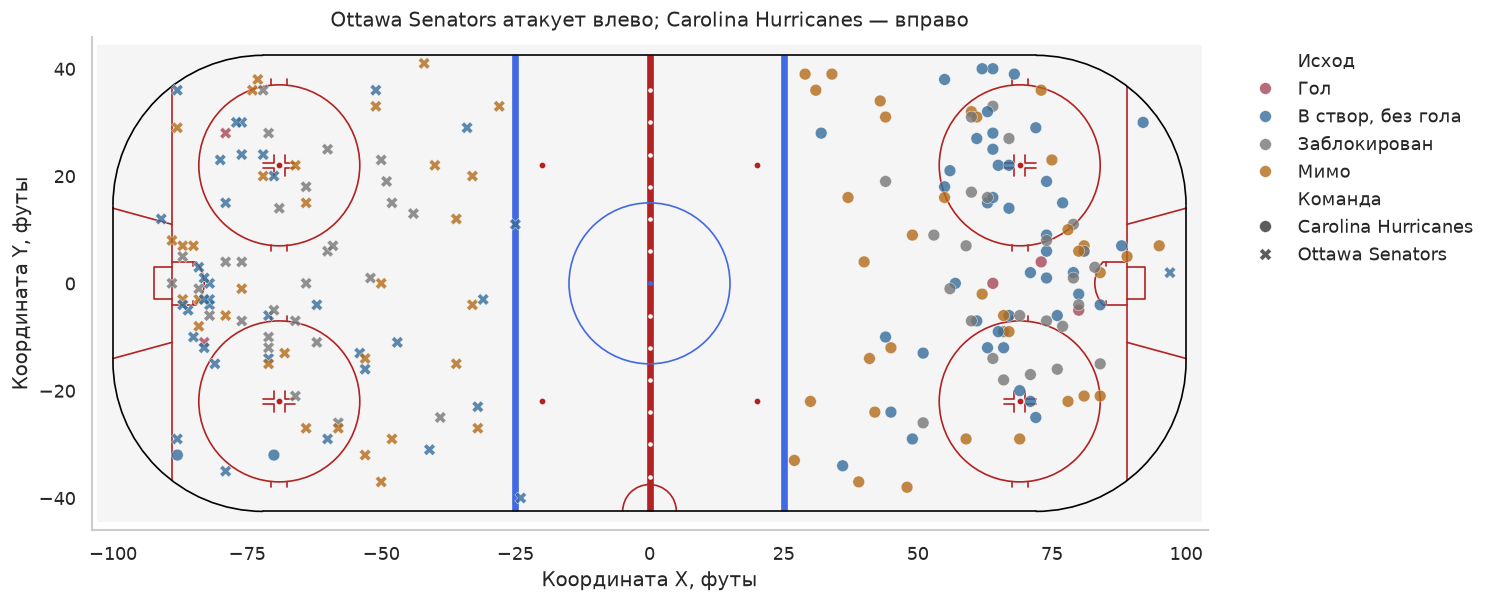

**Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20).** На карте 208 попыток броска. Направление не зависит от периода после поворота. Имена команд для заблокированных событий беру по полю Team Making the Play, а не по Player #1: в блоке Player #1 — блокирующий соперник.

Исход,"В створ, без гола",Гол,Заблокирован,Мимо
Команда,,,,
Carolina Hurricanes,46,3,26,34
Ottawa Senators,37,2,28,32


In [17]:
game_attempts = attempts.loc[attempts['Game ID'].eq(selected_game)].copy()
assert game_attempts[[XCOL, YCOL]].notna().all().all()
rotate = game_attempts["Home Team's Defending Side"].eq('right')
assert rotate.eq(game_attempts['Period'].mod(2).eq(1)).all()
game_attempts['Plot X'] = game_attempts[XCOL].where(~rotate, -game_attempts[XCOL])
game_attempts['Plot Y'] = game_attempts[YCOL].where(~rotate, -game_attempts[YCOL])
game_attempts['Исход'] = game_attempts['Play Type'].map({
    'goal': 'Гол', 'shot-on-goal': 'В створ, без гола',
    'missed-shot': 'Мимо', 'blocked-shot': 'Заблокирован'})
home, away = games.loc[selected_game, ['Home Team', 'Away Team']]
game_attempts['Команда'] = game_attempts['Team Making the Play']
fig, ax = plt.subplots(figsize=(12, 5.8))
plot_rink()
sns.scatterplot(data=game_attempts, x='Plot X', y='Plot Y', hue='Исход', style='Команда',
                hue_order=['Гол', 'В створ, без гола', 'Заблокирован', 'Мимо'],
                palette=['#a44858', '#356d9a', '#777777', '#b36b19'],
                markers={home: 'o', away: 'X'}, s=50, alpha=0.8,
                edgecolor='white', linewidth=0.3, ax=ax)
ax.set_aspect('equal')
ax.set(xlim=(-104, 104), ylim=(-46, 46), xlabel='Координата X, футы', ylabel='Координата Y, футы',
       title=f'{away} атакует влево; {home} — вправо')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
ax.grid(False)
save_figure('15_rink_shots')
say(f'**{gameInfo(selected_game)}.** На карте {len(game_attempts)} попыток броска. '
    'Направление не зависит от периода после поворота. '
    'Имена команд для заблокированных событий беру по полю Team Making the Play, '
    'а не по Player #1: в блоке Player #1 — блокирующий соперник.')
show(pd.crosstab(game_attempts['Команда'], game_attempts['Исход']))

## 16. Десять лучших снайперов
Один гол соответствует одному событию `goal`. Автор гола — `Player in the Event #1`. При равенстве голов сортирую по имени, чтобы результат был воспроизводимым.

In [18]:
def ranking(table, keys, ascending, limit=10):
    result = table.reset_index().sort_values(keys, ascending=ascending).head(limit).reset_index(drop=True)
    if 'Player' in result:
        result['Player'] = result['Player'].map(readable_name)
    return result

assert goals['Player in the Event #1'].notna().all()
scorers = goals['Player in the Event #1'].value_counts().rename_axis('Player').rename('Goals')
top_goals = ranking(scorers.to_frame(), ['Goals', 'Player'], [False, True])
show(top_goals, {'Player': 'Игрок', 'Goals': 'Голов'})
say('Некоторые имена в Excel имеют сбитую UTF-8-кодировку. '
    'В выводе исправляю только однозначно декодируемые имена. Исходные ключи группировки сохранены.')

,Игрок,Голов
№,,
1,Brett Howden,14
2,Pavel Dorofeyev,12
3,Logan Stankoven,11
4,Mitch Marner,10
5,Jordan Staal,8
6,Nikolaj Ehlers,8
7,Alex Newhook,7
8,Jackson Blake,7
9,Mark Stone,7


Некоторые имена в Excel имеют сбитую UTF-8-кодировку. В выводе исправляю только однозначно декодируемые имена. Исходные ключи группировки сохранены.

## 17. Десять лучших ассистентов
Объединяю второго и третьего участников голевого события в один столбец. Каждый непустой участник получает одну передачу. У гола может быть ноль, одна или две передачи; пустые значения не являются игроками.

In [19]:
assists_long = goals[['Game ID', 'Play ID', 'Player in the Event #2',
                      'Player in the Event #3']].melt(id_vars=['Game ID', 'Play ID'],
                                                   value_name='Player').dropna(subset=['Player'])
assert not assists_long.duplicated(['Game ID', 'Play ID', 'Player']).any()
assist_counts = assists_long['Player'].value_counts().rename_axis('Player').rename('Assists')
top_assists = ranking(assist_counts.to_frame(), ['Assists', 'Player'], [False, True])
show(top_assists, {'Player': 'Игрок', 'Assists': 'Передач'})

,Игрок,Передач
№,,
1,Jack Eichel,20
2,Mitch Marner,19
3,Jackson Blake,13
4,Lane Hutson,13
5,Martin Necas,12
6,Nick Suzuki,12
7,Shea Theodore,12
8,Taylor Hall,12
9,Kirill Kaprizov,11


## 18. Десять лучших по системе «гол плюс пас»
Соединяю голы и передачи по имени игрока. Если у игрока есть только голы или только передачи, отсутствующий второй показатель равен нулю. При равенстве очков выше стоит игрок с большим числом голов, затем сортирую по имени.

In [20]:
points = pd.concat([scorers, assist_counts], axis=1).fillna(0).astype(int)
points['Points'] = points['Goals'] + points['Assists']
top_points = ranking(points, ['Points', 'Goals', 'Player'], [False, False, True])
show(top_points, {'Player': 'Игрок', 'Goals': 'Голов', 'Assists': 'Передач', 'Points': 'Очков'})
assert points['Goals'].sum() == len(goals)
assert points['Assists'].sum() == len(assists_long)

,Игрок,Голов,Передач,Очков
№,,,,
1,Mitch Marner,10,19,29
2,Jack Eichel,2,20,22
3,Jackson Blake,7,13,20
4,Taylor Hall,7,12,19
5,Brett Howden,14,4,18
6,Nikolaj Ehlers,8,10,18
7,Shea Theodore,6,12,18
8,Pavel Dorofeyev,12,4,16
9,Logan Stankoven,11,5,16


## 19. Десять игроков с наибольшим числом бросков в створ за матч
Знаменатель — число уникальных игр игрока в таблице участий из пункта 7. Это позволяет учесть игры, в которых игрок выходил на лёд, но не нанёс ни одного броска в створ. Числитель включает `shot-on-goal` и `goal`. Порог числа матчей не ввожу. При равенстве среднего использую суммарное число бросков, затем имя.

In [21]:
player_games = appearances[['Game ID', 'Player']].drop_duplicates().groupby('Player').size().rename('Games')
accurate = shots.loc[shots['Accurate']]
# Даже участники гола с пустым составом должны наблюдаться в других событиях той же игры.
actor_games = accurate[['Game ID', 'Player in the Event #1']].rename(
    columns={'Player in the Event #1': 'Player'}).drop_duplicates()
assert actor_games.merge(appearances[['Game ID', 'Player']].drop_duplicates(),
                         on=['Game ID', 'Player'], how='left', indicator=True)['_merge'].eq('both').all()
player_shots = accurate['Player in the Event #1'].value_counts().rename_axis('Player').rename('Shots')
shot_rates = player_games.to_frame().join(player_shots).fillna({'Shots': 0})
shot_rates['Shots'] = shot_rates['Shots'].astype(int)
shot_rates['Shots per Game'] = shot_rates['Shots'] / shot_rates['Games']
top_shot_rates = ranking(shot_rates, ['Shots per Game', 'Shots', 'Player'], [False, False, True])
show(top_shot_rates, {'Player': 'Игрок', 'Games': 'Матчей', 'Shots': 'Бросков в створ',
                      'Shots per Game': 'Бросков в створ за матч'})

,Игрок,Матчей,Бросков в створ,Бросков в створ за матч
№,,,,
1,Jason Robertson,6,30,5.000
2,Dylan Guenther,6,27,4.500
3,Nikita Kucherov,7,31,4.429
4,Matt Boldy,11,48,4.364
5,Quinton Byfield,4,17,4.250
6,Darren Raddysh,7,28,4.000
7,Joel Eriksson Ek,6,24,4.000
8,Alex Laferriere,4,15,3.750
9,David Pastrnak,6,22,3.667


## 20. Десять игроков с наибольшим числом силовых приёмов за матч
Числитель — число событий `hit`, где игрок указан первым участником. Это игрок, который провёл силовой приём, а не тот, против кого его провели. Знаменатель тот же, что в пункте 19, включая игры без силовых приёмов.

In [22]:
hits = events.loc[events['Play Type'].eq('hit')]
assert hits['Player in the Event #1'].notna().all()
hit_counts = hits['Player in the Event #1'].value_counts().rename_axis('Player').rename('Hits')
hit_rates = player_games.to_frame().join(hit_counts).fillna({'Hits': 0})
hit_rates['Hits'] = hit_rates['Hits'].astype(int)
hit_rates['Hits per Game'] = hit_rates['Hits'] / hit_rates['Games']
top_hits = ranking(hit_rates, ['Hits per Game', 'Hits', 'Player'], [False, False, True])
show(top_hits, {'Player': 'Игрок', 'Games': 'Матчей', 'Hits': 'Силовых приёмов',
                'Hits per Game': 'Силовых приёмов за матч'})
assert hit_rates['Hits'].sum() == len(hits)

,Игрок,Матчей,Силовых приёмов,Силовых приёмов за матч
№,,,,
1,Lawson Crouse,6,38,6.333
2,Alex Turcotte,1,6,6.000
3,Alexander Petrovic,1,6,6.000
4,Yakov Trenin,9,51,5.667
5,Dylan Cozens,4,22,5.500
6,Vasily Podkolzin,6,32,5.333
7,Ivan Barbashev,22,110,5.000
8,Marcus Foligno,11,55,5.000
9,Carl Grundstrom,3,15,5.000


## 21. Вратари, не пропустившие ни одной шайбы хотя бы в одной игре
Нужны все вышедшие вратари, включая заменённых и вышедших на замену. Поэтому командный ноль в итоговом счёте не заменяет персональный подсчёт: один вратарь мог пропустить, а его сменщик — нет.

Для каждого гола определяю защищающуюся команду, затем смотрю её вратаря **на этом событии**. Если состав есть, а вратаря нет, это гол при отсутствии указанного вратаря; его не записываю на сменщика. Но у 22 победных голов в овертайме одновременно пусты оба состава и оба поля вратарей. Это пропуск данных, а не свидетельство пустых ворот.

Даю два результата. **Подтверждённый по записям** список включает вратарей с нулём явно записанных голов, если в этом матче у их команды нет гола с неизвестным вратарём. Он консервативен. **Расширенный список** использует допущение: на победном голе в овертайме остался последний наблюдаемый в этом периоде вратарь. Состав восстанавливается только для полностью пустых записей, а не для обычных замен вратаря на полевого. Показываю все 22 атрибуции и временной разрыв, чтобы допущение можно было проверить.

In [23]:
goalie_parts = []
for side in ('Away', 'Home'):
    goalie_parts.append(events[['Game ID', f'{side} Team', f"{side} Team's Goalie"]].rename(
        columns={f'{side} Team': 'Team', f"{side} Team's Goalie": 'Goalie'}).dropna().drop_duplicates())
goalie_appearances = pd.concat(goalie_parts, ignore_index=True).drop_duplicates()
goalie_goals = goals[['Game ID', 'Play ID', 'Period', 'Elapsed Time', 'Home Team', 'Away Team',
                     'Team Making the Play', "Home Team's Goalie", "Away Team's Goalie"]].copy()
away_scored = goalie_goals['Team Making the Play'].eq(goalie_goals['Away Team'])
goalie_goals['Team'] = goalie_goals['Home Team'].where(away_scored, goalie_goals['Away Team'])
goalie_goals['Goalie'] = goalie_goals["Home Team's Goalie"].where(
    away_scored, goalie_goals["Away Team's Goalie"])
lineup_cols = [f"{side} Team's Player on the Ice #{i}" for side in ('Away', 'Home') for i in range(1, 7)]
missing_lineups = events[lineup_cols].isna().all(axis=1)
goalie_goals['Unknown'] = missing_lineups.loc[goalie_goals.index]
assert goalie_goals.loc[goalie_goals['Unknown'], 'Goalie'].isna().all()
assert goalie_goals.loc[goalie_goals['Unknown'], 'Period'].gt(3).all()

def goalie_results(assignments):
    conceded = assignments.dropna(subset=['Goalie']).groupby(['Game ID', 'Team', 'Goalie']).size()
    result = goalie_appearances.set_index(['Game ID', 'Team', 'Goalie']).copy()
    result['Conceded'] = conceded.reindex(result.index, fill_value=0)
    unknown_keys = pd.MultiIndex.from_frame(
        assignments.loc[assignments['Unknown'], ['Game ID', 'Team']].drop_duplicates())
    result['Team Has Unknown Goal'] = result.index.droplevel('Goalie').isin(unknown_keys)
    return result.reset_index()

strict_goalies = goalie_results(goalie_goals)
confirmed_zero = strict_goalies.loc[strict_goalies['Conceded'].eq(0) &
                                    ~strict_goalies['Team Has Unknown Goal']].copy()

# Сохраняю последнее наблюдаемое состояние целиком: пустой вратарь внутри
# непустого состава остаётся пустым и не заменяется предыдущей фамилией.
states = ordered.copy()
states['Row Position'] = np.arange(len(states))
states['Has Lineup'] = ~states[lineup_cols].isna().all(axis=1)
states['Last Valid Position'] = states['Row Position'].where(states['Has Lineup'])
states['Last Valid Position'] = states.groupby(['Game ID', 'Period'])['Last Valid Position'].ffill()
source_position = states.loc[goalie_goals.index[goalie_goals['Unknown']], 'Last Valid Position']
assert source_position.notna().all()
previous = states.iloc[source_position.astype(int).to_numpy()].copy()
previous.index = source_position.index
previous_away_scored = goalie_goals.loc[previous.index, 'Team Making the Play'].eq(previous['Away Team'])
inferred_goalie = previous["Home Team's Goalie"].where(previous_away_scored, previous["Away Team's Goalie"])
assert inferred_goalie.notna().all()
inferred_assignments = goalie_goals.copy()
inferred_assignments.loc[previous.index, 'Goalie'] = inferred_goalie
inferred_assignments.loc[previous.index, 'Unknown'] = False
inferred_results = goalie_results(inferred_assignments)
inferred_zero = inferred_results.loc[inferred_results['Conceded'].eq(0)].copy()

def clock_seconds(series):
    return series.str.split(':').map(lambda pair: int(pair[0]) * 60 + int(pair[1]))

attributions = goalie_goals.loc[previous.index, ['Game ID', 'Team', 'Period', 'Elapsed Time']].copy()
attributions['Goalie'] = inferred_goalie
attributions['Previous Time'] = previous['Elapsed Time']
attributions['Gap Seconds'] = (clock_seconds(attributions['Elapsed Time']) -
                              clock_seconds(attributions['Previous Time']))
assert attributions['Gap Seconds'].ge(0).all()
say('**Голы с восстановленным вратарём:**')
show(attributions.reset_index(drop=True), {'Game ID': 'ID матча', 'Team': 'Защищающаяся команда',
     'Period': 'Период', 'Elapsed Time': 'Время гола', 'Goalie': 'Последний вратарь',
     'Previous Time': 'Время состава', 'Gap Seconds': 'Разрыв, секунд'})

def zero_summary(zero):
    result = zero.groupby('Goalie').agg(Team=('Team', lambda s: ', '.join(sorted(s.unique()))),
                                      Games=('Game ID', 'nunique')).reset_index()
    return result.sort_values(['Games', 'Goalie'], ascending=[False, True]).reset_index(drop=True)

say('**Подтверждённый по заполненным записям список:**')
show(zero_summary(confirmed_zero), {'Goalie': 'Вратарь', 'Team': 'Команда', 'Games': 'Игр без пропущенных'})
say('**Список при допущении последнего наблюдаемого состава:**')
show(zero_summary(inferred_zero), {'Goalie': 'Вратарь', 'Team': 'Команда', 'Games': 'Игр без пропущенных'})
details = inferred_zero[['Game ID', 'Team', 'Goalie']].copy()
details['Матч'] = details['Game ID'].map(gameInfo)
strict_keys = set(map(tuple, confirmed_zero[['Game ID', 'Team', 'Goalie']].to_numpy()))
details['Основание'] = [
    'Прямые записи' if tuple(row) in strict_keys else 'Последний состав в овертайме'
    for row in details[['Game ID', 'Team', 'Goalie']].to_numpy()]
say('**Матчи, на которых основан расширенный список:**')
show(details.reset_index(drop=True), {'Game ID': 'ID матча', 'Team': 'Команда', 'Goalie': 'Вратарь'})
empty_net_goals = goalie_goals['Goalie'].isna() & ~goalie_goals['Unknown']
say(f'В выгрузке **{int(empty_net_goals.sum())} гола** при заполненном составе без '
    f'указанного вратаря и **{int(goalie_goals["Unknown"].sum())} гола** с отсутствующим составом. '
    f'В подтверждённом списке {confirmed_zero["Goalie"].nunique()} вратарей, '
    f'в расширенном — {inferred_zero["Goalie"].nunique()}. '
    'Выход на часть матча с нулём пропущенных здесь засчитан по условию, '
    'хотя это не обязательно официальный вратарский «сухой матч». '
    'Без дополнительного протокола смен нельзя безусловно подтвердить все 22 восстановленные атрибуции.')
assert set(confirmed_zero['Goalie']) == set(inferred_zero['Goalie'])
say('**Итоговый список одинаков при обоих способах:** ' +
    ', '.join(sorted(confirmed_zero['Goalie'].unique())) + '. '
    'Восстановление вратаря на победных голах овертаймов не добавило ни одного имени. '
    'В частности, Joonas Korpisalo и Scott Wedgewood включены за часть игры: '
    'их команды в соответствующих матчах пропускали, а они сами — нет по заполненным записям.')

**Голы с восстановленным вратарём:**

,ID матча,Защищающаяся команда,Период,Время гола,Последний вратарь,Время состава,"Разрыв, секунд"
№,,,,,,,
1,2025030115,Buffalo Sabres,4,09:14,Alex Lyon,08:55,19
2,2025030121,Tampa Bay Lightning,4,01:22,Andrei Vasilevskiy,00:59,23
3,2025030122,Montréal Canadiens,4,12:48,Jakub Dobes,12:42,6
4,2025030123,Tampa Bay Lightning,4,02:09,Andrei Vasilevskiy,02:00,9
5,2025030126,Montréal Canadiens,4,09:03,Jakub Dobes,09:00,3
6,2025030132,Ottawa Senators,5,13:53,Linus Ullmark,13:43,10
7,2025030146,Pittsburgh Penguins,4,17:32,Arturs Silovs,17:23,9
8,2025030152,Los Angeles Kings,4,07:44,Anton Forsberg,07:42,2
9,2025030163,Minnesota Wild,5,12:10,Jesper Wallstedt,11:24,46


**Подтверждённый по заполненным записям список:**

,Вратарь,Команда,Игр без пропущенных
№,,,
1,Frederik Andersen,Carolina Hurricanes,3
2,Dan Vladar,Philadelphia Flyers,2
3,Andrei Vasilevskiy,Tampa Bay Lightning,1
4,Brandon Bussi,Carolina Hurricanes,1
5,Joonas Korpisalo,Boston Bruins,1
6,Scott Wedgewood,Colorado Avalanche,1


**Список при допущении последнего наблюдаемого состава:**

,Вратарь,Команда,Игр без пропущенных
№,,,
1,Frederik Andersen,Carolina Hurricanes,3
2,Dan Vladar,Philadelphia Flyers,2
3,Andrei Vasilevskiy,Tampa Bay Lightning,1
4,Brandon Bussi,Carolina Hurricanes,1
5,Joonas Korpisalo,Boston Bruins,1
6,Scott Wedgewood,Colorado Avalanche,1


**Матчи, на которых основан расширенный список:**

,ID матча,Команда,Вратарь,Матч,Основание
№,,,,,
1,2025030126,Tampa Bay Lightning,Andrei Vasilevskiy,"Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)",Прямые записи
2,2025030142,Philadelphia Flyers,Dan Vladar,"Pittsburgh Penguins - Philadelphia Flyers (0 - 3, Final, 2026-04-20)",Прямые записи
3,2025030314,Carolina Hurricanes,Frederik Andersen,"Montréal Canadiens - Carolina Hurricanes (0 - 4, Final, 2026-05-27)",Прямые записи
4,2025030416,Carolina Hurricanes,Brandon Bussi,"Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)",Прямые записи
5,2025030114,Boston Bruins,Joonas Korpisalo,"Boston Bruins - Buffalo Sabres (1 - 6, Final, 2026-04-26)",Прямые записи
6,2025030131,Carolina Hurricanes,Frederik Andersen,"Carolina Hurricanes - Ottawa Senators (2 - 0, Final, 2026-04-18)",Прямые записи
7,2025030146,Philadelphia Flyers,Dan Vladar,"Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)",Прямые записи
8,2025030221,Carolina Hurricanes,Frederik Andersen,"Carolina Hurricanes - Philadelphia Flyers (3 - 0, Final, 2026-05-02)",Прямые записи
9,2025030235,Colorado Avalanche,Scott Wedgewood,"Colorado Avalanche - Minnesota Wild (4 - 3, Final/OT, 2026-05-13)",Прямые записи


В выгрузке **3 гола** при заполненном составе без указанного вратаря и **22 гола** с отсутствующим составом. В подтверждённом списке 6 вратарей, в расширенном — 6. Выход на часть матча с нулём пропущенных здесь засчитан по условию, хотя это не обязательно официальный вратарский «сухой матч». Без дополнительного протокола смен нельзя безусловно подтвердить все 22 восстановленные атрибуции.

**Итоговый список одинаков при обоих способах:** Andrei Vasilevskiy, Brandon Bussi, Dan Vladar, Frederik Andersen, Joonas Korpisalo, Scott Wedgewood. Восстановление вратаря на победных голах овертаймов не добавило ни одного имени. В частности, Joonas Korpisalo и Scott Wedgewood включены за часть игры: их команды в соответствующих матчах пропускали, а они сами — нет по заполненным записям.

## 22. Свой вопрос: как точность зависит от расстояния до ворот?
В пункте 9 сравнивались распределения расстояний при известном исходе. Здесь меняю вопрос: **какая доля незаблокированных бросков с заданной дистанции попадает в створ?** Для ответа делю расстояния на интервалы по 30 футов и внутри каждого считаю долю точных бросков. Для очень дальних бросков оставляю отдельный интервал от 120 футов до максимума. Показываю числитель, знаменатель и 95%-й интервал Уилсона.

Интервалы Уилсона использую как ориентир точности доли при биномиальной модели. Броски внутри одной игры зависимы, поэтому дополнительно строю 95%-й интервал разницы долей между дистанциями меньше 30 и от 30 до 60 футов с бутстрепом **целых матчей**, 2000 повторений, seed = 20261024. Это описательная связь: на неё влияют позиции, тактика и сила соперников.

,В створ,Незаблокированных,Доля в створ,Нижняя граница 95%,Верхняя граница 95%
Distance Bin,,,,,
0–<30,2166,3405,0.636,0.620,0.652
30–<60,1860,2984,0.623,0.606,0.641
60–<90,386,637,0.606,0.567,0.643
90–<120,71,79,0.899,0.813,0.948
120 и дальше,140,161,0.870,0.809,0.913


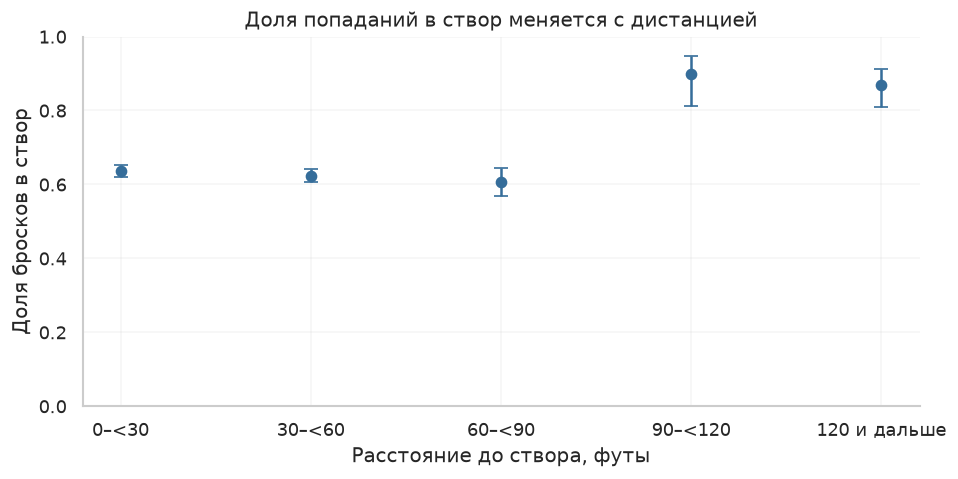

На дистанции меньше 30 футов доля точных бросков — **63.6%**, от 30 до 60 футов — **62.3%**. Разница — **1.3 п.п.**, 95%-й интервал бутстрепа матчей: **[-1.1; 3.7] п.п.** Интервал включает ноль: по этой оценке уверенно различить точность двух ближних диапазонов нельзя. Эти оценки относятся к незаблокированным броскам. На больших расстояниях доля не обязана монотонно снижаться: дальние выбросы, дошедшие до вратаря, тоже попадают в категорию точных бросков. Поэтому доля попаданий в створ сама по себе не равна опасности броска.

In [24]:
edges = [0, 30, 60, 90, 120, np.inf]
labels = ['0–<30', '30–<60', '60–<90', '90–<120', '120 и дальше']
shots['Distance Bin'] = pd.cut(shots['Shot Length'], bins=edges, labels=labels, right=False)
distance_accuracy = shots.groupby('Distance Bin', observed=False)['Accurate'].agg(['sum', 'count'])
distance_accuracy.columns = ['On Goal', 'Unblocked']
distance_accuracy['Share'] = distance_accuracy['On Goal'] / distance_accuracy['Unblocked']
z = stats.norm.ppf(0.975)
n = distance_accuracy['Unblocked']
p = distance_accuracy['Share']
center = (p + z*z / (2*n)) / (1 + z*z/n)
half = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1+z*z/n)
distance_accuracy['Lower 95%'] = center-half
distance_accuracy['Upper 95%'] = center+half
assert n.gt(0).all() and n.sum() == len(shots)
show(distance_accuracy, {'On Goal': 'В створ', 'Unblocked': 'Незаблокированных',
     'Share': 'Доля в створ', 'Lower 95%': 'Нижняя граница 95%', 'Upper 95%': 'Верхняя граница 95%'})

fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(np.arange(5), p, yerr=[p-(center-half), (center+half)-p],
            fmt='o', color='#356d9a', capsize=4, markersize=6)
ax.set(xticks=np.arange(5), xticklabels=labels, ylim=(0, 1),
       xlabel='Расстояние до створа, футы', ylabel='Доля бросков в створ',
       title='Доля попаданий в створ меняется с дистанцией')
save_figure('22_distance_accuracy')

per_game_bins = shots.groupby(['Game ID', 'Distance Bin'], observed=False)['Accurate'].agg(['sum', 'count'])
success = per_game_bins['sum'].unstack().reindex(index=games.index, columns=labels, fill_value=0).to_numpy()
trials = per_game_bins['count'].unstack().reindex(index=games.index, columns=labels, fill_value=0).to_numpy()
rng = np.random.default_rng(20261024)
sample_ids = rng.integers(0, len(games), size=(2000, len(games)))
bootstrap_shares = success[sample_ids].sum(axis=1) / trials[sample_ids].sum(axis=1)
difference = p.iloc[0] - p.iloc[1]
boot_difference = bootstrap_shares[:, 0] - bootstrap_shares[:, 1]
lower, upper = np.quantile(boot_difference, [0.025, 0.975])
say(f'На дистанции меньше 30 футов доля точных бросков — **{p.iloc[0]:.1%}**, '
    f'от 30 до 60 футов — **{p.iloc[1]:.1%}**. Разница — **{difference*100:.1f} п.п.**, '
    f'95%-й интервал бутстрепа матчей: **[{lower*100:.1f}; {upper*100:.1f}] п.п.** '
    'Интервал включает ноль: по этой оценке уверенно различить точность двух ближних диапазонов нельзя. '
    'Эти оценки относятся к незаблокированным броскам. '
    'На больших расстояниях доля не обязана монотонно снижаться: '
    'дальние выбросы, дошедшие до вратаря, тоже попадают в категорию точных бросков. '
    'Поэтому доля попаданий в створ сама по себе не равна опасности броска.')

## Результат
Сверяю итоговые числа между независимыми представлениями: счёт матчей и голевые события, попытки и сумму их типов, участия и знаменатели рейтингов. Сохранённые выводы получены реальным запуском ячеек. Полные рейтинги считаются из исходных строк, а числа из примеров в PDF используются только как внешние контрольные значения.

In [25]:
checks = {
    'Прочитано 29 710 исходных событий': len(events) == 29710,
    'Нет повторов пары Game ID / Play ID': not events.duplicated(['Game ID', 'Play ID']).any(),
    '82 игры, 16 команд': len(games) == 82 and len(avgshots) == 16,
    '486 голов совпадают со счётом всех игр': len(goals) == games['Total Score'].sum() == 486,
    '7 266 незаблокированных бросков': len(shots) == 7266,
    'Все попытки разложены по четырём типам': len(attempts) == len(shots) + events['Play Type'].eq('blocked-shot').sum(),
    'Доли рассчитаны для 164 пар игра / команда': len(numshots) == 164,
    'Голы и броски в створ сверены по командам': int(numshots['On Goal'].sum()) == len(accurate),
    'Броски игроков сверены с событиями': int(shot_rates['Shots'].sum()) == len(accurate),
    'Все расстояния конечны и неотрицательны': bool(np.isfinite(shots['Shot Length']).all() and shots['Shot Length'].ge(0).all()),
    'Во всех пяти рейтингах ровно десять игроков': all(len(t) == 10 for t in [top_goals, top_assists, top_points, top_shot_rates, top_hits]),
    'Все вратарские голы учтены или явно помечены': int(inferred_assignments['Goalie'].notna().sum() + empty_net_goals.sum()) == len(goals),
    'Нет неизвестных атрибуций после оговорённого восстановления': not inferred_assignments['Unknown'].any(),
    'Все голевые авторы присутствуют в своих матчах': actor_games.merge(appearances[['Game ID', 'Player']].drop_duplicates(), on=['Game ID','Player'], how='left', indicator=True)['_merge'].eq('both').all(),
}
assert all(checks.values()), checks
show(pd.DataFrame({'Проверка': checks.keys(), 'Пройдена': [bool(v) for v in checks.values()]}))
versions = {name: importlib.metadata.version(name) for name in
            ['pandas', 'numpy', 'openpyxl', 'matplotlib', 'seaborn', 'scipy']}
say('Python ' + platform.python_version() + '. Пакеты: ' +
    ', '.join(f'`{name} {version}`' for name, version in versions.items()) + '.')
say('Ограничение исходника существенно для пункта 21: отсутствие состава нельзя '
    'превращать в подтверждённый гол в пустые ворота. Прямой и расширенный результаты '
    'показаны раздельно. Остальные расчёты используют исходные значения без заполнения пропусков.')

,Проверка,Пройдена
№,,
1,Прочитано 29 710 исходных событий,True
2,Нет повторов пары Game ID / Play ID,True
3,"82 игры, 16 команд",True
4,486 голов совпадают со счётом всех игр,True
5,7 266 незаблокированных бросков,True
6,Все попытки разложены по четырём типам,True
7,Доли рассчитаны для 164 пар игра / команда,True
8,Голы и броски в створ сверены по командам,True
9,Броски игроков сверены с событиями,True


Python 3.11.15. Пакеты: `pandas 3.0.6`, `numpy 2.4.6`, `openpyxl 3.1.5`, `matplotlib 3.11.2`, `seaborn 0.13.2`, `scipy 1.17.1`.

Ограничение исходника существенно для пункта 21: отсутствие состава нельзя превращать в подтверждённый гол в пустые ворота. Прямой и расширенный результаты показаны раздельно. Остальные расчёты используют исходные значения без заполнения пропусков.